<a href="https://colab.research.google.com/github/aisena23/aisena23.github.io/blob/main/Hands_On_Activity_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

In [ ]:
url = "https://github.com/yongmeiwang/AI_BigData_CancerBiology/raw/main/Data/gtex_integrin_7_organs.xlsx"
integrins = pd.read_excel(url)
integrins

,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1982,GTEX-QMRM-0826-SM-3NB33,Lung,5.3067,-3.8160,4.9065,7.5810,5.8714,4.7345,2.6185,3.1095,...,5.6080,3.7324,8.2849,4.6201,3.6440,6.7052,5.1094,3.3364,5.8153,1.6604
1983,GTEX-YFCO-1626-SM-4W1Z3,Prostate,2.9581,-4.6082,1.1641,4.6938,1.5902,5.8625,-0.5125,1.7617,...,3.8798,-1.4699,7.5163,-0.3752,2.9562,5.3035,4.4304,-0.9406,3.6136,0.4233
1984,GTEX-1117F-2826-SM-5GZXL,Breast,4.3184,-6.5064,1.0433,4.8440,3.5498,4.6809,1.0293,3.3478,...,5.3256,-0.0725,7.7516,1.1382,2.1411,7.1132,0.3796,0.0854,3.8650,1.0151
1985,GTEX-Q2AG-2826-SM-2HMJQ,Brain,3.4622,-5.5735,1.5013,5.4835,1.7702,4.7517,0.6790,-3.1714,...,1.1960,4.1740,4.3002,0.5470,-0.9971,3.7982,-0.2498,1.4808,-0.5125,-0.5125


In [ ]:
brain_lung = integrins[integrins['primary_site'].isin(['Brain', 'Lung'])]

# rearrange data
brain_lung_vertical = brain_lung.melt(
    id_vars='primary_site',
    var_name='integrin_gene',
    value_name='expression levels'
)
brain_lung_vertical

,primary_site,integrin_gene,expression levels
0,Brain,Unnamed: 0,GTEX-13QIC-0011-R1a-SM-5O9CJ
1,Lung,Unnamed: 0,GTEX-1399S-1726-SM-5L3DI
2,Lung,Unnamed: 0,GTEX-QXCU-0626-SM-2TC69
3,Lung,Unnamed: 0,GTEX-11EI6-0826-SM-5985V
4,Lung,Unnamed: 0,GTEX-S341-0326-SM-2XCAU
...,...,...,...
40315,Brain,ITGA11,-2.2447
40316,Brain,ITGA11,-2.5479
40317,Lung,ITGA11,1.6604
40318,Brain,ITGA11,-0.5125


In [ ]:
brain_lung = integrins[integrins['primary_site'].isin(['Brain', 'Lung'])]

#Drop the Unnamed column if it exists so it doesn't mess up the melt
if 'Unnamed: 0' in brain_lung.columns:
  brain_lung = brain_lung.drop(columns=['Unnamed: 0'])

  # Rearrange data cleanly
  brain_lung_vertical = brain_lung.melt(
      id_vars='primary_site',
      var_name='integrin_gene',
      value_name='expression_levels'

  )
  brain_lung_vertical

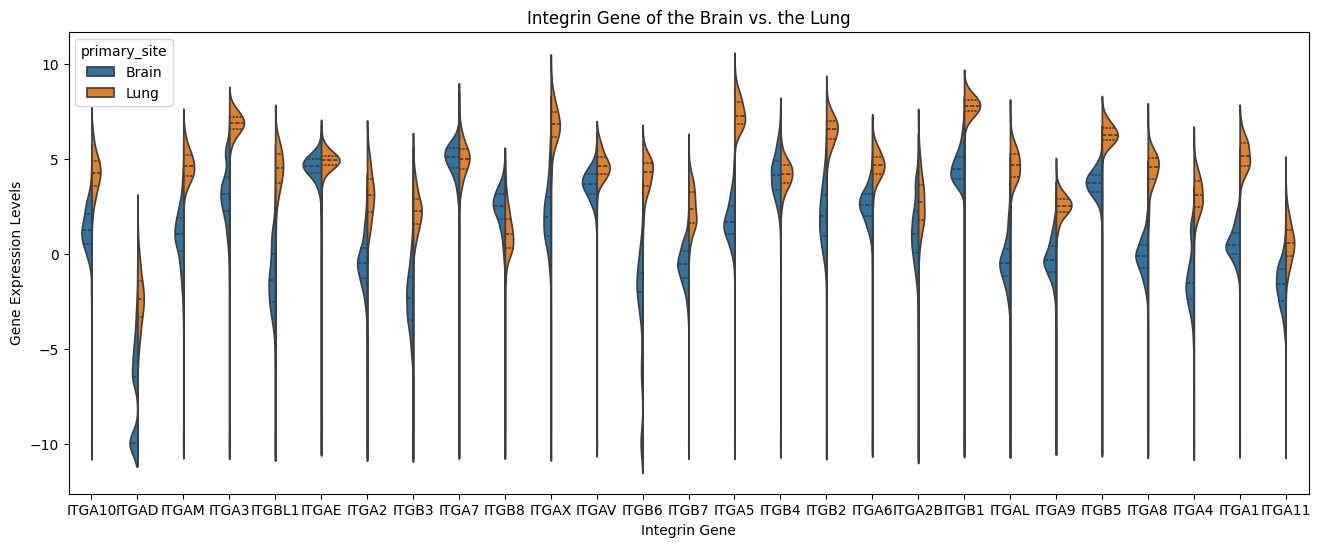

In [ ]:
plt.figure(figsize=(16,6))
sns.violinplot(
    x='integrin_gene',
    y='expression_levels',
    hue='primary_site',
    data=brain_lung_vertical,
    split=True,
    inner="quartile"
)
plt.title("Integrin Gene of the Brain vs. the Lung")
plt.xlabel("Integrin Gene")
plt.ylabel("Gene Expression Levels")
plt.legend(title='primary_site')
plt.show()

In [ ]:
#choosing integrin ITGA1 will give good performance, since we can see from the violin plot that the gene expression levels are more clearly distinct

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = brain_lung[['ITGA1']]   #a data frame; independent variable (only the ITGA1 gene expression is used as input to the model)
y = brain_lung['primary_site']   #dependent variable (label trying to predict (brain or lung))

#define split between train and test;
#training the model on one portion of the data and evaluating it on another
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42) #70% training data, 30% testing data

#define model used: logistic regression
model = LogisticRegression()
model.fit(X_train, y_train)  #trains model, Learn relationship between ITGA1 expression and tissue type



y_pred = model.predict(X_test)  #use trained model to predict tissue types for test data (not seen during training)
accuracy = accuracy_score(y_test, y_pred)  #compare predicted labels to true labels, calculates accuracy of predictions
print(f"Accuracy using ITGA1: {accuracy:.2f}")  #accuracy percentage (rounded to 2 decimal places).

Accuracy using ITGA1: 1.00


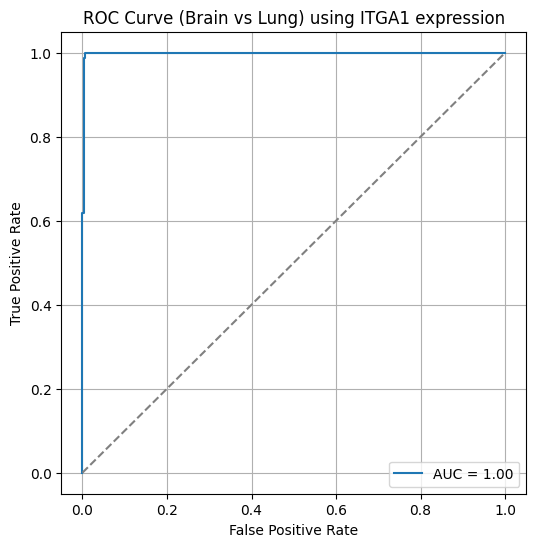

In [ ]:
#AUROC curve
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

X = brain_lung[['ITGA1']]
y = brain_lung['primary_site'].map({'Brain': 0, 'Lung': 1})  #binary encoding, negative and positive

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

model = LogisticRegression()
model.fit(X_train, y_train)

#predict probabilities
y_proba = model.predict_proba(X_test)[:, 1]  #probabilities for "lung"

#compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

#plot
plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr, label = f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'gray')  # random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Brain vs Lung) using ITGA1 expression')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#switch ITGA1 to ITGA11, accuracy will decrease, based on split violin plot, since means of gene expression for each tissue are similar

X = brain_lung[['ITGA11']]
y = brain_lung['primary_site']

#define split between train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state = 42) #60% training data, 40% testing data

#define model used: logistic regression
model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy using ITGA11: {accuracy:.2f}")

Accuracy using ITGA11: 0.89


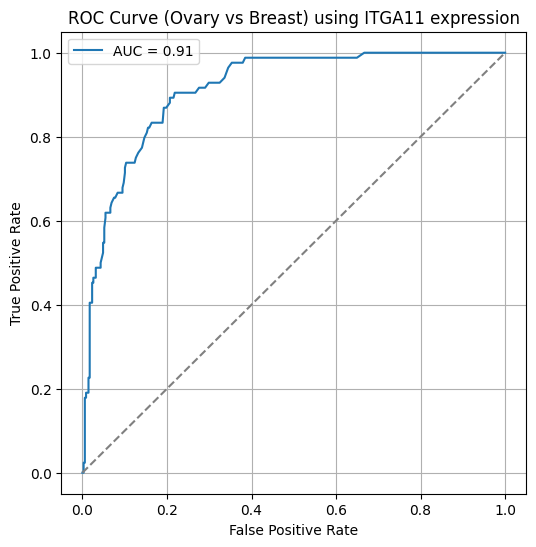

In [ ]:
#AUROC curve
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

X = brain_lung[['ITGA11']]
y = brain_lung['primary_site'].map({'Brain': 0, 'Lung': 1})  #binary encoding, negative and positive

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

model = LogisticRegression()
model.fit(X_train, y_train)

#predict probabilities
y_proba = model.predict_proba(X_test)[:, 1]  #probabilities for "lung"

#compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

#plot
plt.figure(figsize = (6, 6))
plt.plot(fpr, tpr, label = f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'gray')  # random guess line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Ovary vs Breast) using ITGA11 expression')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


selected_genes = ['ITGA1', 'ITGA11']
#X = integrins.iloc[:, -27:]  # Assuming the last 27 columns are integrins
X = integrins[selected_genes]
y = integrins['primary_site']

#encode organ labels as numbers
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size = 0.2, random_state = 42)

#train multinomial logistic regression
#model = LogisticRegression(multi_class = 'multinomial', solver = 'lbfgs', max_iter = 1000)
#Scikit-learn defaults to multinomial when lbfgs is used, warning message if code includes multi-class = 'multinomial' because it will become outdated
model = LogisticRegression(solver = 'lbfgs', max_iter = 1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names = le.classes_))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8618090452261307

Classification Report:
              precision    recall  f1-score   support

 Bone Marrow       0.78      0.70      0.74        10
       Brain       0.96      0.98      0.97       247
      Breast       0.65      0.55      0.59        44
       Liver       0.95      0.83      0.88        23
        Lung       0.70      0.93      0.80        43
       Ovary       0.38      0.50      0.43        10
    Prostate       0.58      0.33      0.42        21

    accuracy                           0.86       398
   macro avg       0.72      0.69      0.69       398
weighted avg       0.86      0.86      0.86       398


Confusion Matrix:
[[  7   3   0   0   0   0   0]
 [  2 241   1   0   0   3   0]
 [  0   3  24   0   9   4   4]
 [  0   0   0  19   4   0   0]
 [  0   0   2   1  40   0   0]
 [  0   3   1   0   0   5   1]
 [  0   0   9   0   4   1   7]]


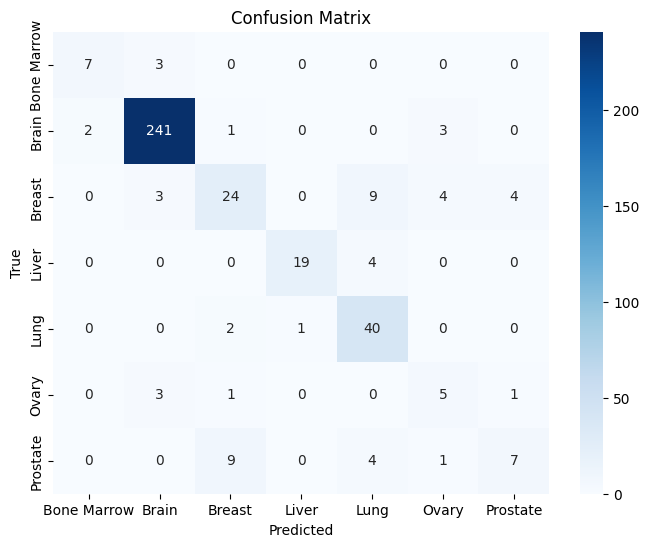

In [ ]:
#format the confusion matrix for visual
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)   #compute raw confusion matrix
plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = le.classes_, yticklabels = le.classes_)
#annot add numbers in cells, fmt format as integers, cmap blue color gradient, ticklabels shows class (tissue type) names
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

## Reflection Section

**1. How does binary classification differ from multi-class classification?**
> *Binary classification handles two categories. For example, this code is mainly sorted into brain and lung.
Multi-class classification has three or more categories. Such as, the seven organs as categories that were used to sort in
parts of this code.*

**2. What does a confusion matrix reveal in multi-class settings?**
>*In general, a confusion matrix asseses the performance of a multi-class model based on prediction
and actual finding. In this code, the confusion matrix highlights whether data was sorted into an organ's category  
correctly or not sorted correctly.This betters our understanding of the multi-class model's advantages
as well as its shortcomings.*

**3. Why might some tissues be harder to classify?**
>*Some tissues share a similar structure or function, overlap or blend into neighboring areas, suffer damage, etc...
The model may not accurately sort the data because of these reasons as well as because of the sample's quality or
its size.*

**4. Does classification performance imply biological causation?**
>* No, classification performance does not necessarily impy biological causation. The model may be able to
identify patterns and reveal relationships. The model may have found a strong tie, but it does not mean it is the root
cause. Like most scientific methods, additional testing, experiments, and trials must be perfromed to have definitive proof.*